In [ ]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt

# Load Dataset
df = pd.read_csv("/content/weatherHistory.csv")
df.head()

,Formatted Date,Summary,Precip Type,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Loud Cover,Pressure (millibars),Daily Summary
0,2006-04-01 00:00:00.000 +0200,Partly Cloudy,rain,9.472222,7.388889,0.89,14.1197,251.0,15.8263,0.0,1015.13,Partly cloudy throughout the day.
1,2006-04-01 01:00:00.000 +0200,Partly Cloudy,rain,9.355556,7.227778,0.86,14.2646,259.0,15.8263,0.0,1015.63,Partly cloudy throughout the day.
2,2006-04-01 02:00:00.000 +0200,Mostly Cloudy,rain,9.377778,9.377778,0.89,3.9284,204.0,14.9569,0.0,1015.94,Partly cloudy throughout the day.
3,2006-04-01 03:00:00.000 +0200,Partly Cloudy,rain,8.288889,5.944444,0.83,14.1036,269.0,15.8263,0.0,1016.41,Partly cloudy throughout the day.
4,2006-04-01 04:00:00.000 +0200,Mostly Cloudy,rain,8.755556,6.977778,0.83,11.0446,259.0,15.8263,0.0,1016.51,Partly cloudy throughout the day.


In [ ]:
# Remove missing values
df = df.dropna()

# Encode target column
le = LabelEncoder()
df["Summary"] = le.fit_transform(df["Summary"])

# Select numerical features
X = df.select_dtypes(include=["float64", "int64"]).drop("Summary", axis=1)
y = df["Summary"]

# Scale features
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Convert to PyTorch tensors
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

y_train = torch.tensor(y_train.values, dtype=torch.long)
y_test = torch.tensor(y_test.values, dtype=torch.long)

In [ ]:
# Tensor Example
a = torch.tensor([[1,2],[3,4]], dtype=torch.float32)
b = torch.tensor([[5,6],[7,8]], dtype=torch.float32)

print("Addition:\n", a+b)
print("Multiplication:\n", a*b)

# Autograd Example
x = torch.tensor(2.0, requires_grad=True)
y = x**2 + 3*x + 2

y.backward()

print("Gradient:", x.grad)

Addition:
 tensor([[ 6.,  8.],
        [10., 12.]])
Multiplication:
 tensor([[ 5., 12.],
        [21., 32.]])
Gradient: tensor(7.)


In [ ]:
class WeatherModel(nn.Module):
    def __init__(self, input_size, output_size):
        super().__init__()
        self.fc1 = nn.Linear(input_size, 64)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(64, output_size)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        return self.fc2(x)

model = WeatherModel(X_train.shape[1], len(torch.unique(y_train)))

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

losses = []

for epoch in range(50):
    outputs = model(X_train)
    loss = criterion(outputs, y_train)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    losses.append(loss.item())

print("Training Completed")

Training Completed


In [ ]:
with torch.no_grad():
    outputs = model(X_test)
    _, predicted = torch.max(outputs, 1)

accuracy = accuracy_score(y_test, predicted)

print("Accuracy:", accuracy)

print("\nConfusion Matrix")
print(confusion_matrix(y_test, predicted))

print("\nClassification Report")
print(classification_report(y_test, predicted))

Accuracy: 0.3584010840108401

Confusion Matrix
[[   0    0    0    0    0    1    0    0    0    0    0    0    0    0
     0    6    2    0    0    0    0    0    0]
 [   0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    1    5    0    0    0    0    0    0]
 [   0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0   87    4    4    0    0    0    0    0]
 [   0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0   87   21    0    0    0    0    0    0]
 [   0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0   57    7   13    0    0    0    0    0]
 [   0    0    0    0    0   98    0    0    0    0   41    0    0    0
     0  946  744  332    0    0    0    0    0]
 [   0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    2    6    0    0    0    0    0    0]
 [   0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    7    0    0    0    0

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


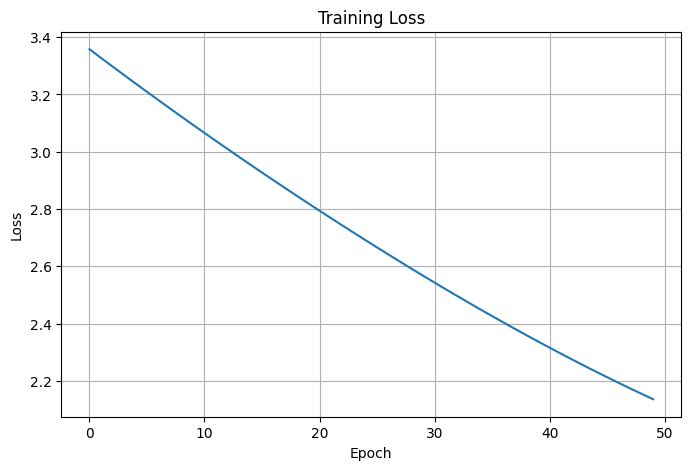


Conclusion:
1. Weather dataset was successfully loaded and preprocessed.
2. PyTorch tensors and Autograd were demonstrated.
3. Neural network model was built and trained successfully.
4. The model was evaluated using Accuracy, Confusion Matrix, and Classification Report.
5. Training loss decreased over epochs, indicating effective learning.



In [ ]:
# Loss Curve
plt.figure(figsize=(8,5))
plt.plot(losses)
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

print("""
Conclusion:
1. Weather dataset was successfully loaded and preprocessed.
2. PyTorch tensors and Autograd were demonstrated.
3. Neural network model was built and trained successfully.
4. The model was evaluated using Accuracy, Confusion Matrix, and Classification Report.
5. Training loss decreased over epochs, indicating effective learning.
""")